# Figure S11F — CAID3 Disorder-PDB, IDRs ≥100 aa: ranking by MCC (top 40)

CAID3 disorder predictors ranked by MCC at each method's Fmax threshold, scoring only the disordered residues in IDRs of ≥100 residues (plus every ordered residue; see Figure S11A for how the bins are made). metapredict V1, V2 and V3 are coloured wherever they fall within the top 40. An asterisk marks a predictor whose MCC is significantly higher than metapredict V3's.

**Significance.** Paired bootstrap over targets, as in the CAID assessments: targets are resampled with replacement 1,000 times, each predictor ahead of V3 and V3 itself are scored on the same resampled targets, and a predictor is significantly ahead if the central 95% interval of (predictor − V3) lies above zero. The bootstrap uses a fast re-implementation of the pooled metrics, which is checked against the CAID3 scoring code before it runs. The cell below prints the result for all four metrics.

**Output:** `figures/figure_S11F.pdf`

In [1]:
import matplotlib.pyplot as plt

from caid3_panels import load_predictions, load_reference, print_metapredict_ranks, rank_predictors
from figtools import apply_style, require_metapredict_3_1, save_panel
from idr_length import (IDR_LENGTH_BINS, METRIC_LABELS, paired_bootstrap, ranking_panel,
                        significantly_ahead, stratify_reference)

apply_style()
require_metapredict_3_1()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

TOP_N = 40
shortest, longest, label = IDR_LENGTH_BINS[3]  # IDRs of ≥100 residues

metapredict 3.1.0+7.g7dcf52c.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)


In [2]:
predictions = load_predictions()
binned = stratify_reference(load_reference(), shortest, longest)
ranking = rank_predictors(binned, predictions, dataset=f'IDRs {label} aa')
print_metapredict_ranks(ranking)

AUC   V1 0.907 (rank 43/66), V2 0.937 (rank 25/66), V3 0.954 (rank 7/66)
APS   V1 0.825 (rank 39/66), V2 0.876 (rank 16/66), V3 0.917 (rank 5/66)
FMAX  V1 0.751 (rank 39/66), V2 0.826 (rank 13/66), V3 0.871 (rank 4/66)
MCC   V1 0.679 (rank 39/66), V2 0.778 (rank 12/66), V3 0.835 (rank 4/66)


In [3]:
# paired bootstrap of every predictor ahead of V3 on some metric (~10-30 s)
intervals = paired_bootstrap(binned, predictions, ranking)
for attr, metric in METRIC_LABELS.items():
    ahead = intervals[attr]
    significant = significantly_ahead(ahead)
    print(f'{metric}: {len(ahead)} ahead of V3, {len(significant)} significantly')
    for name, (lower, upper) in sorted(ahead.items(), key=lambda item: -item[1][0]):
        print(f'    {name:22s} difference 95% interval {lower:+.3f} to {upper:+.3f}')

AUC: 6 ahead of V3, 2 significantly
    PUNCH2                 difference 95% interval +0.005 to +0.022
    PUNCH2-Light           difference 95% interval +0.002 to +0.021
    AlphaFold-rsa          difference 95% interval -0.002 to +0.020
    LMDisorder             difference 95% interval -0.009 to +0.013
    AlphaFold3-rsa         difference 95% interval -0.009 to +0.017
    SPOT-Disorder2         difference 95% interval -0.011 to +0.008
APS: 4 ahead of V3, 1 significantly
    PUNCH2                 difference 95% interval +0.002 to +0.034
    PUNCH2-Light           difference 95% interval -0.001 to +0.030
    AlphaFold-rsa          difference 95% interval -0.019 to +0.024
    SPOT-Disorder2         difference 95% interval -0.033 to +0.020
Fmax: 3 ahead of V3, 1 significantly
    PUNCH2                 difference 95% interval +0.003 to +0.048
    PUNCH2-Light           difference 95% interval -0.001 to +0.045
    AlphaFold-rsa          difference 95% interval -0.021 to +0.028
MCC: 3 

Wrote figures/figure_S11F.pdf


PosixPath('figures/figure_S11F.pdf')

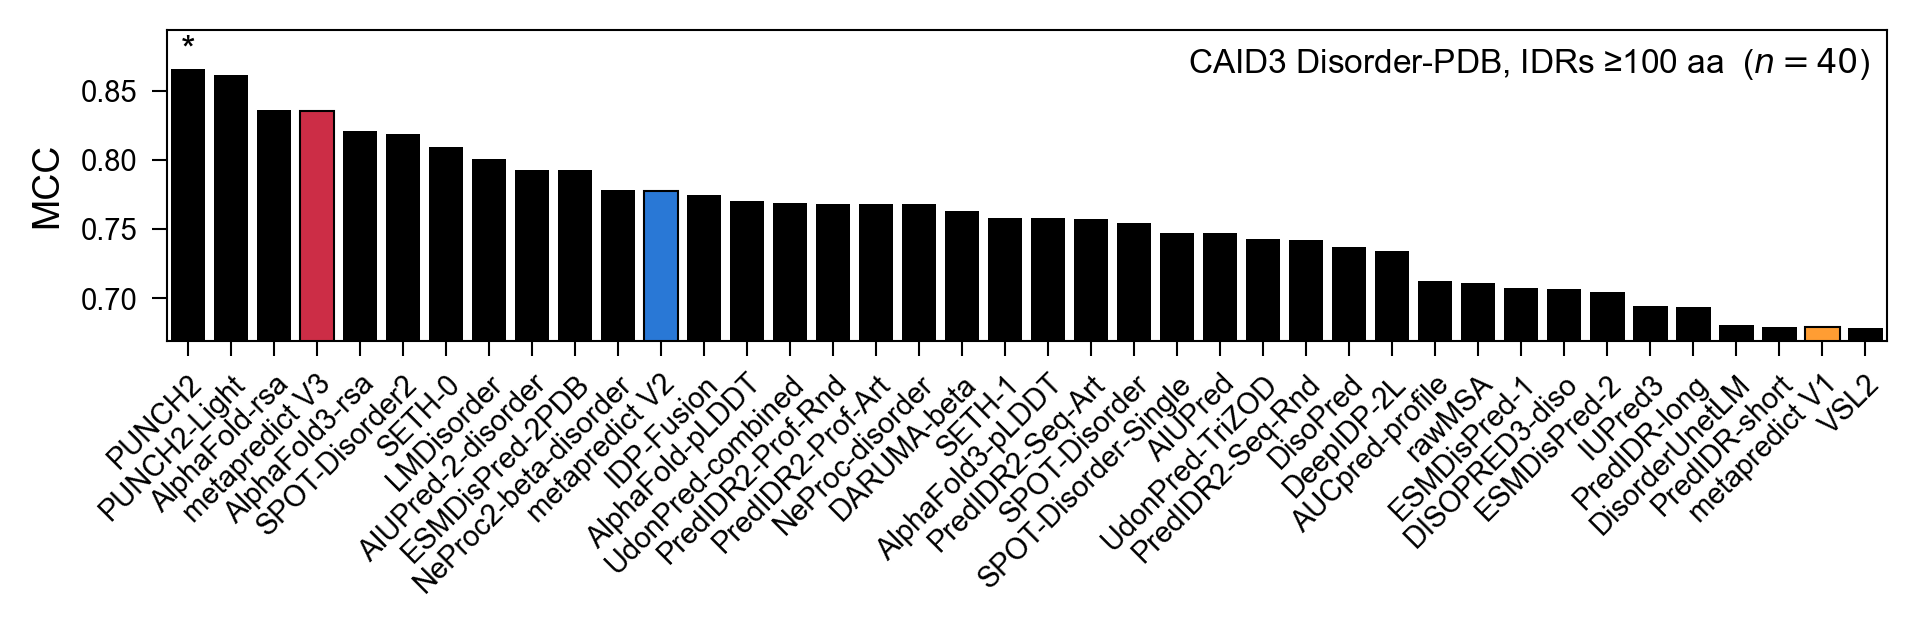

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 2.2), dpi=150)
ranking_panel(ax, ranking, 'mcc', f'CAID3 Disorder-PDB, IDRs {label} aa', significantly_ahead(intervals['mcc']),
              top_n=TOP_N)
plt.tight_layout()
save_panel(fig, 'figure_S11F')